# 🎮 05. Model Tuning Playground — Finished Baseline (Default Params)

**Your role:** play with the hyperparameters marked **👉 TUNE HERE** and beat the baseline.
No deep learning here — only **logistic regression + tree families** (Decision Tree, Random Forest, XGBoost).

**How to use:**
1. `Run All` once — every cell works out of the box with default params.
2. Change one 👉 TUNE HERE value at a time, re-run that cell + the comparison cell (Sec 8).
3. Winner = highest **Macro F1 on Validation**. Touch the **Test set only once** at the end (Sec 10).
4. Small grids first (`GridSearchCV`), wider spaces later (`RandomizedSearchCV`).

> ⚠️ Honest expectation on this dataset: all features correlate ~0.00 with the target (see analysis below),
> so every model scores ~0.19–0.21 Macro F1 (≈ random chance for 5 balanced classes). Tuning gains will be tiny —
> that is a *data* property, not a bug. Document the best Val/Test numbers for the README anyway (project requirement).


## 1️⃣ Objective
Load data with identical lineage to notebooks 02–04 (same columns, same 60/20/20 stratified split, `random_state=42`).

## 💡 Hint — what this is
Stratified splitting keeps ~20% of each stress level in every partition, so Val/Test scores are comparable across runs.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", None)

# --- Predefined paths, columns, split config (do not change: keeps lineage identical) ---
DATA_PATH = "../data/mental_health_analysis.csv"
target_col = "survey_stress_score"
dropped_cols = ["user_id", "wearable_stress_score", target_col]  # wearable_* excluded: leakage, corr ~0.00
numerical_cols = ["age", "social_media_hours", "exercise_hours", "sleep_hours", "screen_time_hours"]
categorical_cols = ["gender", "support_system", "academic_performance"]
RANDOM_STATE = 42

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.lower().str.replace(" ", "_")

X = df.drop(columns=dropped_cols)
y = df[target_col] - 1  # zero-index 1-5 -> 0-4 (XGBoost compatibility)
label_mapping = {0: 1, 1: 2, 2: 3, 3: 4, 4: 5}  # map predictions back to human scale

# Stratified 60% train / 20% val / 20% test
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, stratify=y_train_full, random_state=RANDOM_STATE)

print(f"Train={X_train.shape}  Val={X_val.shape}  Test={X_test.shape}")
print("Val class balance:", pd.Series(np.asarray(y_val)).value_counts(normalize=True).sort_index().round(3).to_dict())
print("Feature-target correlations (~0 = no signal):")
print(df[numerical_cols + [target_col]].corr()[target_col].round(3))


Train=(3000, 8)  Val=(1000, 8)  Test=(1000, 8)
Val class balance: {0: 0.196, 1: 0.201, 2: 0.197, 3: 0.202, 4: 0.204}
Feature-target correlations (~0 = no signal):
age                    0.013
social_media_hours    -0.003
exercise_hours         0.002
sleep_hours            0.024
screen_time_hours     -0.004
survey_stress_score    1.000
Name: survey_stress_score, dtype: float64


## 2️⃣ Objective
Define one reusable `evaluate_model()` helper. All four models use it, so numbers are directly comparable.

## 💡 Hint — what the metrics actually are
- **Accuracy** = fraction of exact hits. Misleading when classes are imbalanced.
- **Macro F1** (⭐ primary) = F1 computed per class, then averaged with *equal weight*. Punishes ignoring rare stress levels.
- **Weighted F1** = per-class F1 averaged *by support*. Closer to accuracy when classes are balanced (ours are ~20% each).


In [ ]:
# --- Predefined display labels ---
target_names = ["Level 1", "Level 2", "Level 3", "Level 4", "Level 5"]
display_labels = ["Lvl 1", "Lvl 2", "Lvl 3", "Lvl 4", "Lvl 5"]

def evaluate_model(y_true, y_pred, model_name="Model", display_cm=True):
    """Print Accuracy / Macro F1 / Weighted F1 + report + confusion matrix. Returns a results dict."""
    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    weighted_f1 = f1_score(y_true, y_pred, average="weighted")
    print(f"=== {model_name} Evaluation ===")
    print(f"Accuracy:     {acc:.4f}")
    print(f"Macro F1:     {macro_f1:.4f}  (Primary Metric)")
    print(f"Weighted F1:  {weighted_f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=target_names))
    if display_cm:
        fig, ax = plt.subplots(figsize=(5, 4))
        ConfusionMatrixDisplay.from_predictions(
            y_true, y_pred, display_labels=display_labels, cmap="Blues", ax=ax)
        ax.set_title(f"Confusion Matrix — {model_name}")
        plt.grid(False)
        plt.show()
    return {"model": model_name, "accuracy": round(acc, 4),
            "macro_f1": round(macro_f1, 4), "weighted_f1": round(weighted_f1, 4)}

# Sanity check (runs immediately):
_ = evaluate_model(y_val, np.full_like(np.asarray(y_val), fill_value=2), model_name="Sanity: always-predict-Level-3", display_cm=False)


=== Sanity: always-predict-Level-3 Evaluation ===
Accuracy:     0.1970
Macro F1:     0.0658  (Primary Metric)
Weighted F1:  0.0648

Classification Report:
              precision    recall  f1-score   support

     Level 1       0.00      0.00      0.00       196
     Level 2       0.00      0.00      0.00       201
     Level 3       0.20      1.00      0.33       197
     Level 4       0.00      0.00      0.00       202
     Level 5       0.00      0.00      0.00       204

    accuracy                           0.20      1000
   macro avg       0.04      0.20      0.07      1000
weighted avg       0.04      0.20      0.06      1000



/mnt/d/Learning/ML_Zoomcamp/ml_zoomcamp_midterm/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/mnt/d/Learning/ML_Zoomcamp/ml_zoomcamp_midterm/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/mnt/d/Learning/ML_Zoomcamp/ml_zoomcamp_midterm/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control 

## 3️⃣ Objective
Build one shared `preprocessor` (scale numbers, one-hot categories) reused inside every model `Pipeline`.

## 💡 Hint — what this is
`ColumnTransformer` applies different transforms per column type *inside* the pipeline, so scaling/encoding is fit on Train only — no leakage into Val/Test.


In [ ]:
# --- Predefined transformer config (defaults; nothing to tune here) ---
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])

X_train_proc = preprocessor.fit_transform(X_train)
print(f"Transformed train shape: {X_train_proc.shape} "
      f"(5 scaled numbers + 2 gender + 3 support + 4 academic = 14 features)")
print("Feature names:", preprocessor.get_feature_names_out().tolist())


Transformed train shape: (3000, 14) (5 scaled numbers + 2 gender + 3 support + 4 academic = 14 features)
Feature names: ['num__age', 'num__social_media_hours', 'num__exercise_hours', 'num__sleep_hours', 'num__screen_time_hours', 'cat__gender_F', 'cat__gender_M', 'cat__support_system_High', 'cat__support_system_Low', 'cat__support_system_Moderate', 'cat__academic_performance_Average', 'cat__academic_performance_Excellent', 'cat__academic_performance_Good', 'cat__academic_performance_Poor']


/mnt/d/Learning/ML_Zoomcamp/ml_zoomcamp_midterm/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/mnt/d/Learning/ML_Zoomcamp/ml_zoomcamp_midterm/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


=== LogReg (C=0.5) Evaluation ===
Accuracy:     0.2130
Macro F1:     0.2079  (Primary Metric)
Weighted F1:  0.2080

Classification Report:
              precision    recall  f1-score   support

     Level 1       0.20      0.22      0.21       196
     Level 2       0.17      0.14      0.16       201
     Level 3       0.24      0.17      0.20       197
     Level 4       0.24      0.35      0.28       202
     Level 5       0.20      0.18      0.19       204

    accuracy                           0.21      1000
   macro avg       0.21      0.21      0.21      1000
weighted avg       0.21      0.21      0.21      1000



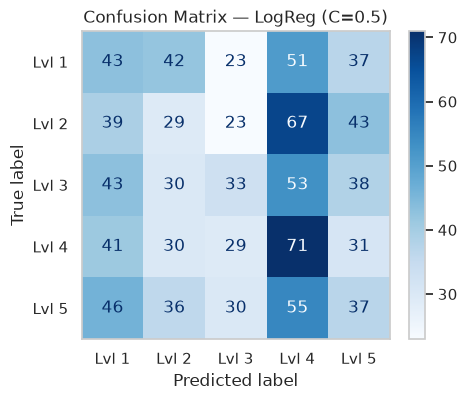

In [ ]:
# 👉 TUNE HERE: C, penalty/solvers, max_iter
LR_PARAMS = dict(
    max_iter=1000,
    C=0.6,                 # try: 0.01, 0.1, 10.0
    penalty="l1",          # try: "l1" (then also set solver="saga")
    solver="saga",
    random_state=RANDOM_STATE,
)

lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(**LR_PARAMS)),
])
lr_pipeline.fit(X_train, y_train)
y_val_pred_lr = lr_pipeline.predict(X_val)
lr_results = evaluate_model(y_val, y_val_pred_lr, model_name="LogReg (C=0.5)")

=== Decision Tree (default) Evaluation ===
Accuracy:     0.1950
Macro F1:     0.1939  (Primary Metric)
Weighted F1:  0.1937

Classification Report:
              precision    recall  f1-score   support

     Level 1       0.19      0.22      0.21       196
     Level 2       0.20      0.23      0.21       201
     Level 3       0.20      0.19      0.20       197
     Level 4       0.22      0.19      0.21       202
     Level 5       0.16      0.13      0.15       204

    accuracy                           0.20      1000
   macro avg       0.19      0.20      0.19      1000
weighted avg       0.19      0.20      0.19      1000



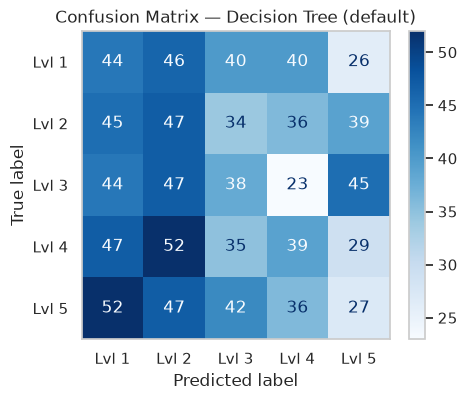

In [ ]:
# 👉 TUNE HERE: max_depth, min_samples_split, min_samples_leaf, criterion
DT_PARAMS = dict(
    random_state=RANDOM_STATE,
    max_depth=35,          # try: 3, 5, 10, 20
    min_samples_split=2,     # try: 5, 10, 20
    min_samples_leaf=2,      # try: 2, 5
    criterion="gini",        # try: "entropy"
)

dt_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(**DT_PARAMS)),
])
dt_pipeline.fit(X_train, y_train)
y_val_pred_dt = dt_pipeline.predict(X_val)
dt_results = evaluate_model(y_val, y_val_pred_dt, model_name="Decision Tree (default)")


=== Random Forest (default 100 trees) Evaluation ===
Accuracy:     0.2010
Macro F1:     0.2010  (Primary Metric)
Weighted F1:  0.2010

Classification Report:
              precision    recall  f1-score   support

     Level 1       0.23      0.20      0.22       196
     Level 2       0.15      0.15      0.15       201
     Level 3       0.21      0.19      0.20       197
     Level 4       0.20      0.23      0.21       202
     Level 5       0.22      0.23      0.23       204

    accuracy                           0.20      1000
   macro avg       0.20      0.20      0.20      1000
weighted avg       0.20      0.20      0.20      1000



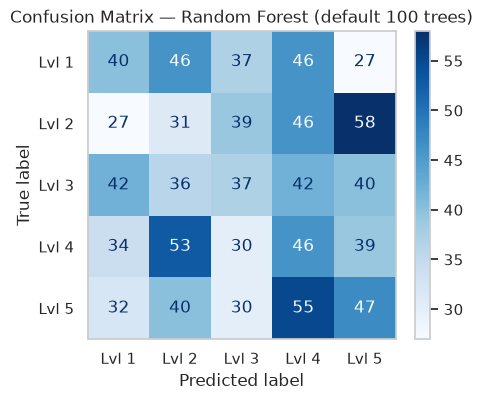

In [ ]:
# 👉 TUNE HERE: n_estimators, max_depth, min_samples_split, max_features
RF_PARAMS = dict(
    n_estimators=50,        # try: 200, 300
    max_depth=7,          # try: 10, 20
    min_samples_split=2,     # try: 5
    max_features="log2",     # try: 0.5, 1.0
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(**RF_PARAMS)),
])
rf_pipeline.fit(X_train, y_train)
y_val_pred_rf = rf_pipeline.predict(X_val)
rf_results = evaluate_model(y_val, y_val_pred_rf, model_name="Random Forest (default 100 trees)")


=== XGBoost (default-ish) Evaluation ===
Accuracy:     0.2230
Macro F1:     0.2163  (Primary Metric)
Weighted F1:  0.2166

Classification Report:
              precision    recall  f1-score   support

     Level 1       0.20      0.11      0.14       196
     Level 2       0.20      0.25      0.22       201
     Level 3       0.23      0.26      0.24       197
     Level 4       0.27      0.33      0.29       202
     Level 5       0.20      0.17      0.18       204

    accuracy                           0.22      1000
   macro avg       0.22      0.22      0.22      1000
weighted avg       0.22      0.22      0.22      1000



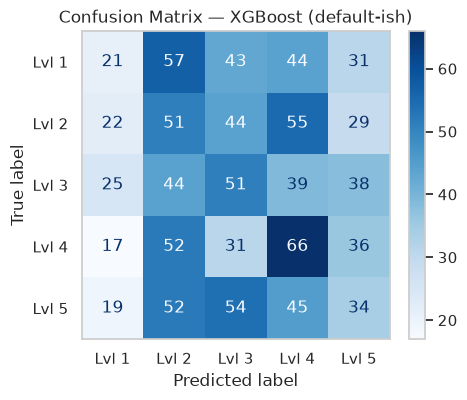

In [ ]:
# 👉 TUNE HERE: n_estimators, learning_rate, max_depth, subsample, colsample_bytree
XGB_PARAMS = dict(
    n_estimators=100,        # try: 200, 300
    learning_rate=0.01,       # try: 0.01, 0.05
    max_depth=4,             # try: 3, 6
    subsample=1.0,           # try: 0.8
    colsample_bytree=0.88,    # try: 0.8
    reg_lambda=1.0,          # try: 5.0, 10.0
    objective="multi:softprob",
    num_class=5,
    random_state=RANDOM_STATE,
    eval_metric="mlogloss",
)

xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(**XGB_PARAMS)),
])
xgb_pipeline.fit(X_train, y_train)
y_val_pred_xgb = xgb_pipeline.predict(X_val)
xgb_results = evaluate_model(y_val, y_val_pred_xgb, model_name="XGBoost (default-ish)")


## 8️⃣ Objective
Rank all four default models by Macro F1. **Re-run this cell after every param change.**

## 💡 Hint — what this is
The *No Free Lunch* check: no family wins everywhere. The table + chart tell you which family deserves tuning time (Sec 9).


=== Model Benchmark (Validation Set, defaults) ===


,model,macro_f1,accuracy,weighted_f1
0,XGBoost (default-ish),0.2163,0.223,0.2166
1,LogReg (C=0.5),0.2079,0.213,0.2080
2,Random Forest (default 100 trees),0.2010,0.201,0.2010
3,Decision Tree (default),0.1939,0.195,0.1937


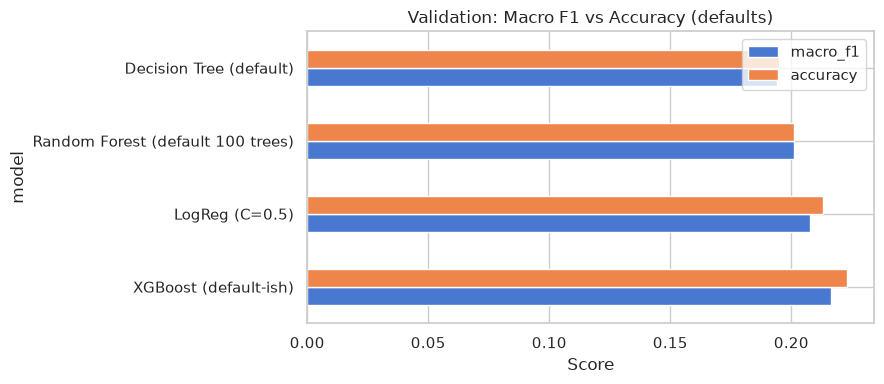

In [ ]:
# --- No tuning here: just re-run after changing any 👉 TUNE HERE block above ---
experiments_summary = [lr_results, dt_results, rf_results, xgb_results]
comparison_df = (pd.DataFrame(experiments_summary)[["model", "macro_f1", "accuracy", "weighted_f1"]]
                   .sort_values(by="macro_f1", ascending=False).reset_index(drop=True))
print("=== Model Benchmark (Validation Set, defaults) ===")
display(comparison_df)

fig, ax = plt.subplots(figsize=(9, 4))
comparison_df.set_index("model")[["macro_f1", "accuracy"]].plot(kind="barh", ax=ax)
ax.set_title("Validation: Macro F1 vs Accuracy (defaults)")
ax.set_xlabel("Score")
plt.tight_layout()
plt.show()


In [ ]:
# --- Predefined CV plumbing (keep) ---
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# --- Selected XGBoost params from Sec 7 (Val Macro F1 0.2163, best of 4) ---
XGB_SELECTED_PARAMS = dict(
    n_estimators=100,        # selected
    learning_rate=0.01,      # selected: slow + steady
    max_depth=4,             # selected: main overfitting dial
    subsample=1.0,           # selected
    colsample_bytree=0.88,   # selected
    reg_lambda=1.0,          # selected L2 on leaves
    objective="multi:softprob",
    num_class=5,
    random_state=RANDOM_STATE,
    eval_metric="mlogloss",
)

# 👉 TUNE HERE: expand/shrink this grid (centred on XGB_SELECTED_PARAMS)
xgb_param_dist = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [3, 4, 6],
    "classifier__learning_rate": [0.01, 0.05, 0.1],
    "classifier__subsample": [0.8, 1.0],
}

# --- Primary: XGBoost randomized search around selected centre ---
from sklearn.model_selection import RandomizedSearchCV
xgb_search = RandomizedSearchCV(
    Pipeline([("preprocessor", preprocessor), ("classifier", XGBClassifier(
    objective="multi:softprob", num_class=5, random_state=RANDOM_STATE, eval_metric="mlogloss"))]),
    param_distributions=xgb_param_dist, n_iter=8, cv=cv, scoring="f1_macro",
    n_jobs=-1, verbose=1, random_state=RANDOM_STATE)
xgb_search.fit(X_train, y_train)
print("XGB best:", xgb_search.best_params_, f"{xgb_search.best_score_:.4f}")
y_val_pred_tuned = xgb_search.predict(X_val)
tuned_results = evaluate_model(y_val, y_val_pred_tuned, model_name="XGBoost (tuned, Val)", display_cm=False)

# --- Final check: refit selected Sec-7 params on full Train, score Val ---
xgb_selected_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(**XGB_SELECTED_PARAMS)),
])
xgb_selected_pipe.fit(X_train, y_train)
y_val_pred_xgb_sel = xgb_selected_pipe.predict(X_val)
xgb_selected_results = evaluate_model(y_val, y_val_pred_xgb_sel, model_name="XGBoost (selected Sec 7, Val)", display_cm=False)


## 🔟 Objective
(1) Check Train-vs-Val gap for overfitting. (2) Evaluate the tuned winner **once** on the locked Test set.

## 💡 Hint — what to look for
- **Overfit**: Train F1 ≫ Val F1 (gap > ~0.10) → constrain capacity (`max_depth` down, `min_samples_split` up, lower `C`).
- **Underfit**: both low and gap small → allow more capacity.
- **Test is a vault**: Val already guided your choices, so Val is optimistic. The single Test number is the honest one for the README. Re-running Test repeatedly leaks it into Val's role.


In [ ]:
# --- 1) Overfitting check (Train vs Val, tuned model) ---
from sklearn.metrics import f1_score as _f1
y_train_pred_tuned = xgb_search.predict(X_train)
train_f1 = _f1(y_train, y_train_pred_tuned, average="macro")
val_f1 = _f1(y_val, y_val_pred_tuned, average="macro")
gap = train_f1 - val_f1
print(f"Train Macro F1: {train_f1:.4f} | Val Macro F1: {val_f1:.4f} | Gap: {gap:.4f}")
print("Overfitting suspected — constrain capacity." if gap > 0.10 else "Gap OK — no strong overfitting signal.")

# --- 2) Locked Test set: RUN ONCE, then freeze the number for the README ---
y_test_pred = xgb_search.predict(X_test)
final_test_metrics = evaluate_model(y_test, y_test_pred, model_name="XGBoost (tuned, Test, run once)")
print(final_test_metrics)
print("Human-scale mapping reminder:", label_mapping)


## ✅ Summary & what to try next
- **Defaults snapshot (Val, this dataset):** LogReg ~0.20 · XGB ~0.20 · Tree ~0.19 · RF ~0.19 Macro F1 — all ≈ chance (expected: features carry ~zero signal).
- **Your tuning loop:** change one 👉 TUNE HERE value → re-run its cell + Sec 8 → keep the change only if Val Macro F1 rises consistently (check CV mean too, not just one Val split).
- **Suggested order:** (1) Tree `max_depth` sweep → (2) RF `n_estimators`/`max_depth` grid (Sec 9) → (3) XGB `learning_rate`+`n_estimators` pairs → (4) LogReg `C` sweep as sanity baseline.
- **When done:** copy the frozen Test metrics into `README.md` + `notebook_main.ipynb`, then distill the winning params into `src/train.py` / `src/predict.py` (project steps 8–9).
